In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [31]:
def parse_err_file(keys, log_path, nproc, job_id):
    err_fname = f'{log_path}/cell_neighborhood_tokenization_{nproc}_{job_id}.err'
    with open(err_fname, 'r') as f:
        lines = f.readlines()

    times = {}
        
    for line in lines:
        if 'wandb' in line:
            line = line.split()
    
            for key in keys:
                if key in line:
                    try:
                        times[key] = np.float32(line[-1])
                        break
                    except:
                        continue
    return times

In [32]:
def parse_out_file(keys, log_path, nproc, job_id):
    out_fname = f'{log_path}/cell_neighborhood_tokenization_{nproc}_{job_id}.out'
    with open(out_fname, 'r') as f:
        lines = f.readlines()
    
    keys = {'Max Memory'}

    memory = {}
        
    for line in lines:
        for key in keys:
            if key in line:
                line = line.split()
                try:
                    memory[key] = np.float32(line[-2])/1024
                    break
                except:
                    continue

    return memory

In [33]:
nprocs = [1, 2, 4, 8]
job_ids = ['203837', '227181', '224136', '225271']
log_path = '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/logs/merfish_mouse_brain_8-batch/profile-nprocs'
results = {}
time_keys = ['cumulative_time_create_dataset', 'cumulative_time_tokenize_files', 'tokenization_time']
mem_keys = ['Max Memory']
profiler_keys = time_keys + mem_keys

for nproc, job_id in zip(nprocs, job_ids):
    results[nproc] = parse_err_file(time_keys, log_path, nproc, job_id)
    results[nproc].update(parse_out_file(mem_keys, log_path, nproc, job_id))    

In [34]:
df = pd.DataFrame(results).T
df['nproc'] = nprocs
display(df)

,cumulative_time_create_dataset,cumulative_time_tokenize_files,tokenization_time,Max Memory,nproc
1,117.615479,96.645149,224.831787,5.778320,1
2,122.897926,62.386589,193.096664,23.813477,2
4,104.112129,41.913151,153.393784,22.277344,4
8,72.064598,20.020000,99.311272,19.948242,8


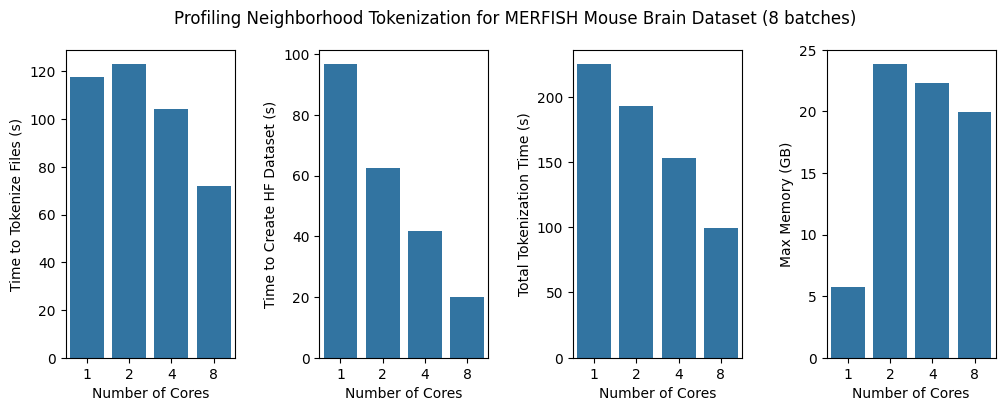

In [35]:
subplots = (1,4)
figsize = (12,4)
fig,ax = plt.subplots(*subplots, figsize=figsize, squeeze=False)

axis_labels = ['Time to Tokenize Files (s)', 'Time to Create HF Dataset (s)', 'Total Tokenization Time (s)', 'Max Memory (GB)']

for i, key in enumerate(profiler_keys):
    sns.barplot(x='nproc', y=key, data=df, ax=ax[0][i])
    ax[0][i].set_xlabel('Number of Cores')
    ax[0][i].set_ylabel(axis_labels[i])
    
fig.suptitle('Profiling Neighborhood Tokenization for MERFISH Mouse Brain Dataset (8 batches)')

plt.subplots_adjust(wspace=0.5, hspace=0.5)
plt.show()